# Main Figure 1: synthetic single-A-line scaling

This notebook belongs to `experiments/REBUTTAL_single_aline_scaling.py`, launched by
`scripts/run_REBUTTAL_single_aline_scaling.sh`. It uses the completed synthetic
runs with N = 25, 50, 100, 200, 500, 1000, 2000, 5000 depth parameters and eight seeds.
It merges the per-seed shards, validates seed coverage, regenerates the plot, and exports
`figures/output/figure1.{pdf,jpeg,png,svg}`. Without raw runs in `outputs/`, it merges
the shards committed under `figures/data/figure1_single_aline_scaling/`.

Legend prefixes identify gradient-free (GF) and gradient-based (GB) optimizers.


In [1]:
from pathlib import Path
import sys, json, shutil
ROOT = Path.cwd() if (Path.cwd() / 'experiments').exists() else Path.cwd().parent
assert (ROOT / 'experiments/REBUTTAL_single_aline_scaling.py').exists()
sys.path.insert(0, str(ROOT))
import experiments.REBUTTAL_single_aline_scaling as synthetic

# A fresh clone has no raw runs, so seed outputs/ from the committed per-seed shards.
raw_dir, staged_dir = Path(synthetic.OUT_DIR), Path(synthetic.STAGE_DIR)
if not any(raw_dir.glob('results_pixels*.json')):
    staged = sorted(staged_dir.glob('results_pixels*_seed*.json'))
    assert staged, f'No shards in {raw_dir} or {staged_dir}'
    raw_dir.mkdir(parents=True, exist_ok=True)
    for f in staged:
        shutil.copy2(f, raw_dir / f.name)
synthetic.merge_shards()

  8 sizes x 8 seeds -> /home/gridsan/groups/erelab/Ajay/DiffOCT-rebuttal/outputs/rebuttal_single_aline_scaling/results_single_aline.json
  Figure saved to /home/gridsan/groups/erelab/Ajay/DiffOCT-rebuttal/outputs/rebuttal_single_aline_scaling/rebuttal_single_aline_scaling.{pdf,jpeg,png,svg}
  [stage] copied 69 files -> /home/gridsan/groups/erelab/Ajay/DiffOCT-rebuttal/figures/data/figure1_single_aline_scaling


In [2]:
data = json.loads((Path(synthetic.OUT_DIR) / 'results_single_aline.json').read_text())
assert sorted(int(k) for k in data if not k.startswith('_')) == synthetic.PIXEL_COUNTS
for n in synthetic.PIXEL_COUNTS:
    for method in synthetic.OPTIMIZER_ORDER:
        row = data[str(n)][method]
        assert row['seeds_present'] == list(range(8))
        assert len(row['seed_mape']) == len(row['seed_ms_per_fwd']) == 8
print('Validated eight sizes, four solvers and eight seeds for the new Figure 1.')


Validated eight sizes, four solvers and eight seeds for the new Figure 1.


Exported new main Figure 1: figure1.pdf, figure1.jpeg, figure1.png, figure1.svg


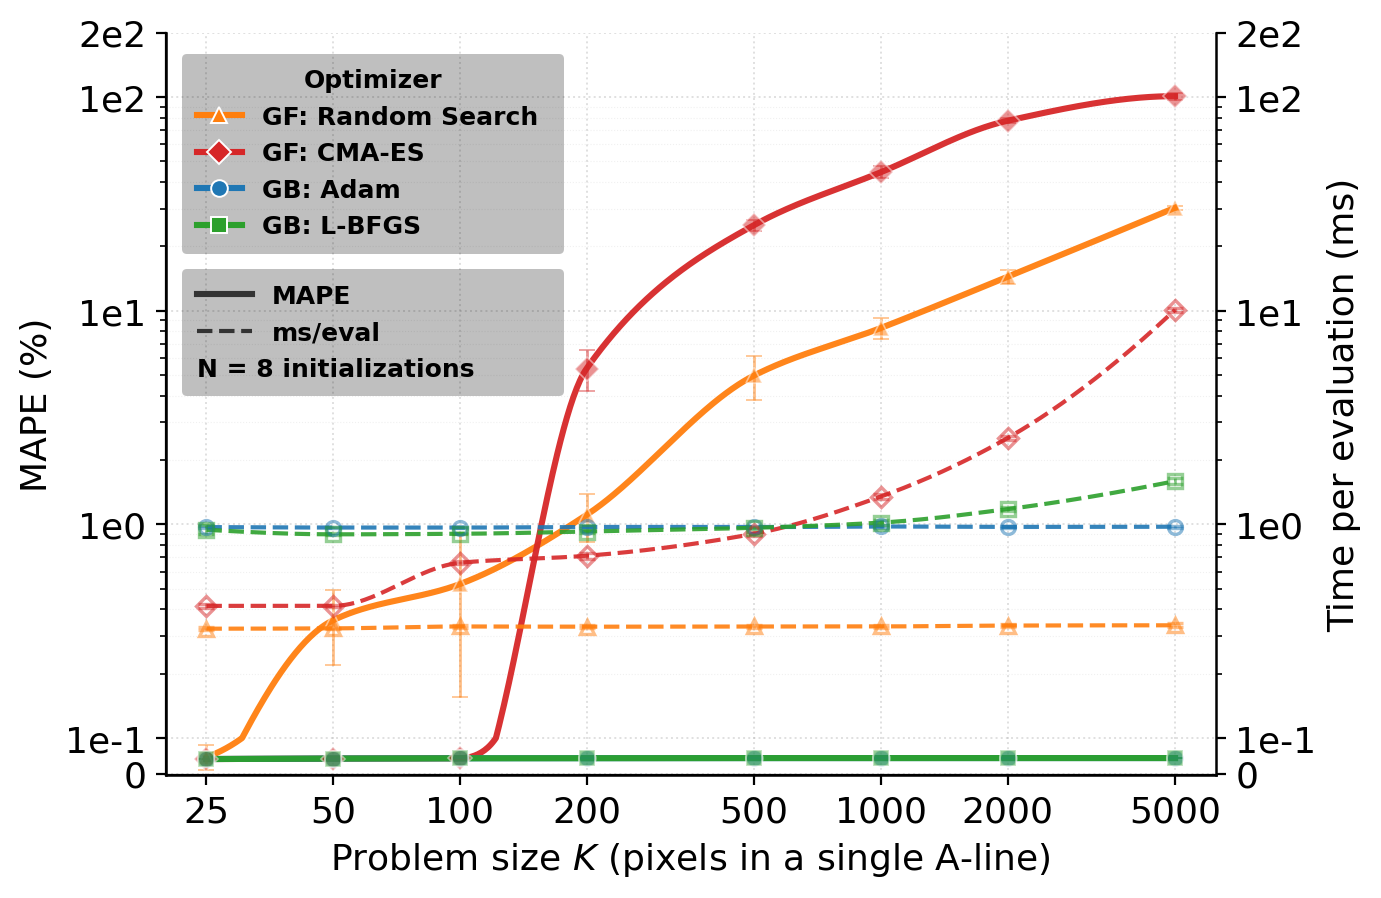

In [3]:
output = ROOT / 'figures/output'
output.mkdir(exist_ok=True)
for suffix in ['pdf', 'jpeg', 'png', 'svg']:
    source = Path(synthetic.OUT_DIR) / f'rebuttal_single_aline_scaling.{suffix}'
    shutil.copy2(source, output / f'figure1.{suffix}')
print('Exported main Figure 1: figure1.pdf, figure1.jpeg, figure1.png, figure1.svg')
from IPython.display import display, Image
display(Image(filename=str(output / 'figure1.png')))